In [100]:
import pandas as pd
import scipy.stats
from scipy.ndimage import gaussian_filter1d, gaussian_filter
from matplotlib import gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.gridspec as gridspec
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
from matplotlib.animation import FuncAnimation, FFMpegWriter
import numpy as np
import umap
from sklearn.decomposition import PCA
from collections import Counter
import torch
import os
import sys

# from BWM.Notebooks.DensityMatching import active_lambda
active_lambda = 0.1 # Default value if not imported
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../../'))
import torch.optim as optim
from BWM.bwm_functions import *


plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7,
    'font.sans-serif': ['Helvetica']
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [101]:
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]



region = "CP"
pseudo_response_tensor, condition_matrix, neuron_eids = get_region_response_matrix(
    eids=eids,
    directory_path=directory_path,
    region=region,
    mapping='Beryl',
    sigma=2,
    n_steps=100,
    threshold=1,
    min_trials_per_condition=50,
    n_pseudo=25,
    conditions=['choice'],
    event="stimOn_times",
    filter_significant=True,
    significance_threshold=0.
)

Aggregating CP responses across 459 EIDs...


Processing EIDs: 100%|██████████| 459/459 [04:48<00:00,  1.59it/s]


Max conditions: 2, Common conditions found: [(np.float32(-1.0),), (np.float32(1.0),)]
Total neurons collected: 11269


In [102]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_pre_pca

In [103]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    #diff_responses = np.diff(response_tensor_norm, axis=1)
    speed= np.mean(np.abs(np.diff(z,axis=1)),axis=(0,1))
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
   # msd = np.mean(np.abs(diff_responses), axis=(0,1))
    return speed



In [104]:
class RNN(torch.nn.Module):
    def __init__(self, n, input_dim, beta, bias):
        super(RNN, self).__init__()
        self.n = n
        self.input_dim = input_dim
        self.beta = beta
        self.bias = bias
        self.activation = torch.nn.Softplus(beta=self.beta)
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        self.recurrent_layer.bias.data.normal_(mean=self.bias, std=0)
        self.recurrent_layer.bias.requires_grad = True
        self.input_layer = nn.Linear(self.input_dim, self.n, bias=False)
        self.alpha = .05
    def forward(self, u, dt, steps):
        batch_size = u.shape[0]
        states = torch.zeros(batch_size, 1, self.n, device=device)
        for i in range(steps - 1):
            state_new = (1 - self.alpha * dt) * states[:, i, :] + self.alpha *dt * (
                self.recurrent_layer(states[:, i, :]) + self.input_layer(u))
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)
        return states


In [105]:
#region = 'CP'
bias = 2
beta = 2
dt = 1
active_lambda = .1
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]

X_input = iso_ae_preprocessing(pseudo_response_tensor)
msd_data = torch.FloatTensor(calculate_msd_data(np.mean(pseudo_response_tensor, axis=0)))
#msd_data = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))


In [106]:
X_input.shape

(9178, 200)

In [107]:
def efficient_variance_explained_svd_vals(responses,top_k):
    x_centered = responses - responses.mean(dim=(0),keepdim=True)
    S = torch.linalg.svdvals(x_centered)
    eigenvalues = S**2
    actual_k = min(top_k,len(eigenvalues))
    return eigenvalues[:actual_k]/eigenvalues.sum()

top_k = 1000
target_fve = efficient_variance_explained_svd_vals(torch.FloatTensor(X_input.T),top_k = top_k).detach()

In [115]:
lr = .0002
steps = 100
n_neurons = pseudo_response_tensor.shape[3]
net = RNN(n=n_neurons, input_dim=1, beta=beta, bias=bias).to(device)
u = torch.FloatTensor(np.linspace(-1, 1, 2)).to(device)
optimizer = optim.Adam(net.parameters(), lr=lr)
criterion = nn.MSELoss()

print("Training RNN...")
for epoch in range(5000):
    optimizer.zero_grad()
    x = net(u.unsqueeze(1), dt, steps)
    x_reshaped = x.reshape(-1, x.shape[2]).T
    activity_penalty = torch.std(torch.mean(x_reshaped, dim=1)) + torch.std(torch.std(x_reshaped, dim=1))
    x_norm = (x_reshaped - torch.mean(x_reshaped, dim=1, keepdim=True)) / (torch.std(x_reshaped, dim=1, keepdim=True) + 1e-8)

    z = (x - torch.mean(x, dim=(0,1), keepdim=True)) / (torch.std(x, dim=(0,1), keepdim=True) + 1e-8)
    msd_rnn = torch.mean(torch.abs(torch.diff(z,dim = 1)),dim = (0,1))

    msd_penalty = criterion(msd_rnn, msd_data)
    fve = efficient_variance_explained_svd_vals(x_norm.t(),top_k = top_k)
    fve_loss = criterion(fve, target_fve)
    loss = 0*criterion(torch.FloatTensor(X_input).to(device), x_norm)  + 0.1 * activity_penalty + fve_loss + msd_penalty
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.4f} | fve = {fve_loss.item():.4f}| Active = {activity_penalty.item():.4f}| Active = {msd_penalty.item():.4f}")

Training RNN...
Epoch 0: Loss = 0.1229 | fve = 0.0006| Active = 1.0843| Active = 0.0138
Epoch 10: Loss = 0.0427 | fve = 0.0020| Active = 0.2573| Active = 0.0151
Epoch 20: Loss = 0.0269 | fve = 0.0020| Active = 0.1050| Active = 0.0143
Epoch 30: Loss = 0.0354 | fve = 0.0008| Active = 0.2141| Active = 0.0132
Epoch 40: Loss = 0.0212 | fve = 0.0015| Active = 0.0727| Active = 0.0123
Epoch 50: Loss = 0.0196 | fve = 0.0012| Active = 0.0753| Active = 0.0109
Epoch 60: Loss = 0.0127 | fve = 0.0003| Active = 0.0595| Active = 0.0064
Epoch 70: Loss = 0.0085 | fve = 0.0003| Active = 0.0395| Active = 0.0043
Epoch 80: Loss = 0.0064 | fve = 0.0003| Active = 0.0292| Active = 0.0032
Epoch 90: Loss = 0.0061 | fve = 0.0003| Active = 0.0323| Active = 0.0026


KeyboardInterrupt: 

<Axes: >

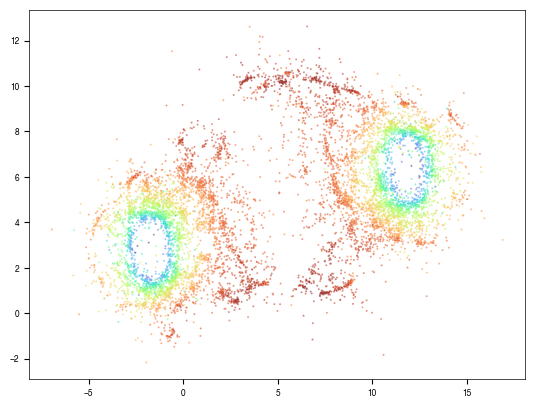

In [116]:
plt.figure()
X_rnn = net(u.unsqueeze(1), dt, 100)
X_rnn_norm = (X_rnn - torch.mean(X_rnn, dim=(0,1), keepdim=True)) / (torch.std(X_rnn, dim=(0,1), keepdim=True) + 1e-8)
msd_rnn = torch.mean(torch.abs(torch.diff(X_rnn_norm, dim=1)), dim=(0,1)).detach().cpu().numpy()
X_rnn_final = X_rnn_norm.reshape(-1, X_rnn_norm.shape[2]).T.detach().cpu().numpy()

z_neurons_rnn = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors=min(500, X_rnn_final.shape[0]-1)).fit_transform(X_rnn_final)
loc_density_rnn = get_density_proxy(torch.FloatTensor(X_rnn_final), k=min(50, X_rnn_final.shape[0]-1)).numpy()

#sns.scatterplot(x=z_neurons_rnn[:, 0], y=z_neurons_rnn[:, 1], color='gray', s=2, alpha=.35)
sns.scatterplot(x=z_neurons_rnn[:, 0], y=z_neurons_rnn[:, 1], c=msd_rnn, cmap='turbo', s=2, alpha=.5)

<Axes: >

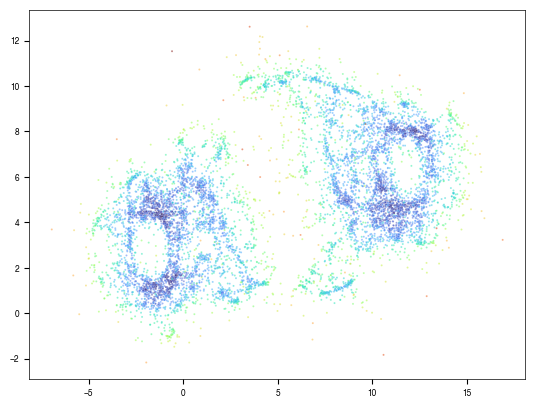

In [117]:
plt.figure()
X_rnn = net(u.unsqueeze(1), dt, 100)
X_rnn_norm = (X_rnn - torch.mean(X_rnn, dim=(0,1), keepdim=True)) / (torch.std(X_rnn, dim=(0,1), keepdim=True) + 1e-8)
msd_rnn = torch.mean(torch.abs(torch.diff(X_rnn_norm, dim=1)), dim=(0,1)).detach().cpu().numpy()
X_rnn_final = X_rnn_norm.reshape(-1, X_rnn_norm.shape[2]).T.detach().cpu().numpy()

#z_neurons_rnn = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors=min(500, X_rnn_final.shape[0]-1)).fit_transform(X_rnn_final)
loc_density_rnn = get_density_proxy(torch.FloatTensor(X_rnn_final), k=min(50, X_rnn_final.shape[0]-1)).numpy()

#sns.scatterplot(x=z_neurons_rnn[:, 0], y=z_neurons_rnn[:, 1], color='gray', s=2, alpha=.35)
sns.scatterplot(x=z_neurons_rnn[:, 0], y=z_neurons_rnn[:, 1], c=loc_density_rnn, cmap='turbo', s=2, alpha=.5)

In [111]:
scipy.stats.pearsonr(loc_density_rnn, msd_rnn)

PearsonRResult(statistic=np.float32(0.35647914), pvalue=np.float64(3.67266866797358e-273))

In [118]:
# Create a movie showing the densmap projection colored by z-scored activity at each moment in time
print("Creating animation...")

# Reshape X_rnn_norm to (n_trials * n_time_points, n_neurons) to use all trials
activity_to_plot = X_rnn_norm.reshape(-1, X_rnn_norm.shape[2]).detach().cpu().numpy()
n_total_points = activity_to_plot.shape[0]
n_time_points = X_rnn_norm.shape[1]
n_trials = X_rnn_norm.shape[0]

fig, ax = plt.subplots(figsize=(8, 6))
# Initial scatter plot with neutral colors
scat = ax.scatter(z_neurons_rnn[:, 0], z_neurons_rnn[:, 1], c=activity_to_plot[0], 
                  cmap='RdBu_r', s=5, alpha=0.7, vmin=-2, vmax=2)
fig.colorbar(scat, label='Z-scored Activity')
ax.set_title(f'Neuron Activity at Time 0')
ax.set_xlabel('DensMAP 1')
ax.set_ylabel('DensMAP 2')

def update(frame):
    scat.set_array(activity_to_plot[frame])
    ax.set_title(f'Neuron Activity at Time {frame}')
    return scat,

ani = FuncAnimation(fig, update, frames=n_total_points, interval=100, blit=True)

# Ensure the Movies directory exists
os.makedirs('../Movies', exist_ok=True)
movie_path = '../Movies/densmap_activity.mp4'
try:
    writer = FFMpegWriter(fps=10)
    ani.save(movie_path, writer=writer)
    print(f"Movie saved to {movie_path}")
except Exception as e:
    print(f"Could not save as mp4, trying gif: {e}")
    movie_path = '../Movies/densmap_activity.gif'
    ani.save(movie_path, writer='pillow', fps=10)
    print(f"Movie saved to {movie_path}")

plt.close(fig)

Creating animation...
Movie saved to ../Movies/densmap_activity.mp4


Locating peak activity...
Observed Localization Density Index (LDI): 1.1710
Observed mean density at peaks: 3.2458 (p=0.0000)
Observed LDI: 1.1710 (p=0.0000)


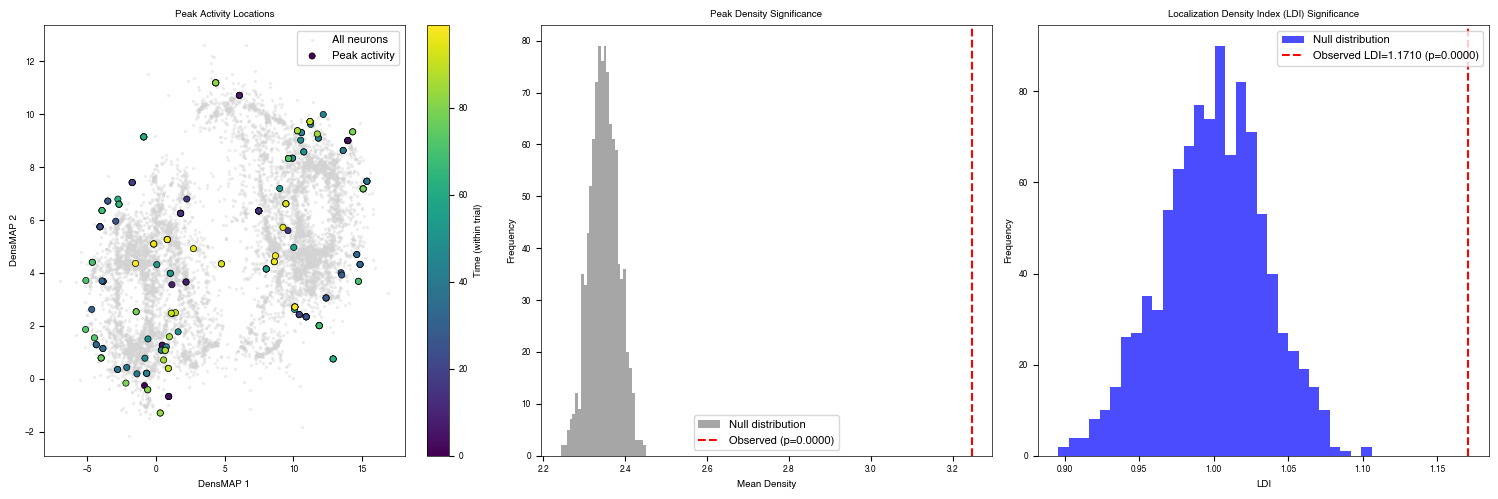

In [119]:
# Locate the location of peak activity in the densmap projection at each moment in time
print("Locating peak activity...")
# activity_to_plot shape: (n_total_points, n_neurons)
# z_neurons_rnn shape: (n_neurons, 2)
# loc_density_rnn shape: (n_neurons,)

# Find the index of the neuron with maximum activity at each time point across all trials
peak_neuron_indices = np.argmax(activity_to_plot, axis=1) # Shape: (n_total_points,)
peak_locations = z_neurons_rnn[peak_neuron_indices] # Shape: (n_total_points, 2)
peak_densities = loc_density_rnn[peak_neuron_indices]

# --- Localization Metric: Activity-Weighted Manifold Density (AWMD) ---
# This metric considers all active neurons, weighted by their activity levels.
# LDI = (Weighted Mean Density) / (Average Manifold Density)
avg_manifold_density = np.mean(loc_density_rnn)

def calculate_ldi(activity, densities):
    # activity: (n_points, n_neurons)
    # densities: (n_neurons,)
    weighted_densities = np.sum(activity * densities, axis=1) / np.sum(activity, axis=1)
    awmd = np.mean(weighted_densities)
    return awmd / avg_manifold_density

observed_ldi = calculate_ldi(activity_to_plot, loc_density_rnn)
print(f"Observed Localization Density Index (LDI): {observed_ldi:.4f}")

# Design a test to determine if these peaks and overall activity are primarily constrained to high density regions
# Null hypothesis: activity patterns are independent of manifold location (randomly permute neurons)
n_shuffles = 1000
null_ldis = []
n_neurons = len(loc_density_rnn)
for _ in range(n_shuffles):
    permuted_indices = np.random.permutation(n_neurons)
    null_ldis.append(calculate_ldi(activity_to_plot, loc_density_rnn[permuted_indices]))

observed_mean_peak_density = np.mean(peak_densities)
p_value_peak = np.mean(np.array(null_densities) >= observed_mean_peak_density) if 'null_densities' in locals() else None # Backwards compatibility check
p_value_ldi = np.mean(np.array(null_ldis) >= observed_ldi)

# Recalculate peak null for consistency if needed, but we already have n_shuffles=10000 above. 
# Let's just stick to the new shuffle for LDI and keep the old one for peak if we want.
# Actually, let's just make one consistent shuffle section.

n_shuffles_consistent = 1000
null_peak_densities = []
null_ldis = []
for _ in range(n_shuffles_consistent):
    perm_idx = np.random.permutation(n_neurons)
    # Null for peak: activity peak at random neuron
    random_peak_indices = np.random.choice(n_neurons, size=n_total_points, replace=True)
    null_peak_densities.append(np.mean(loc_density_rnn[random_peak_indices]))
    # Null for LDI: activity at random locations
    null_ldis.append(calculate_ldi(activity_to_plot, loc_density_rnn[perm_idx]))

observed_peak_density = np.mean(peak_densities)
p_value_peak = np.mean(np.array(null_peak_densities) >= observed_peak_density)
p_value_ldi = np.mean(np.array(null_ldis) >= observed_ldi)

print(f"Observed mean density at peaks: {observed_peak_density:.4f} (p={p_value_peak:.4f})")
print(f"Observed LDI: {observed_ldi:.4f} (p={p_value_ldi:.4f})")

# Visualization
plt.figure(figsize=(15, 5))

# Subplot 1: DensMAP with peaks
plt.subplot(1, 3, 1)
plt.scatter(z_neurons_rnn[:, 0], z_neurons_rnn[:, 1], c='lightgray', s=2, alpha=0.3, label='All neurons')
colors = np.tile(np.arange(n_time_points), n_trials)
plt.scatter(peak_locations[:, 0], peak_locations[:, 1], c=colors, cmap='viridis', s=20, edgecolors='k', linewidths=0.5, label='Peak activity')
plt.colorbar(label='Time (within trial)')
plt.title('Peak Activity Locations')
plt.xlabel('DensMAP 1')
plt.ylabel('DensMAP 2')
plt.legend(fontsize=8)

# Subplot 2: Null distribution of peak densities
plt.subplot(1, 3, 2)
plt.hist(null_peak_densities, bins=30, color='gray', alpha=0.7, label='Null distribution')
plt.axvline(observed_peak_density, color='red', linestyle='--', label=f'Observed (p={p_value_peak:.4f})')
plt.title('Peak Density Significance')
plt.xlabel('Mean Density')
plt.ylabel('Frequency')
plt.legend(fontsize=8)

# Subplot 3: Null distribution of LDI
plt.subplot(1, 3, 3)
plt.hist(null_ldis, bins=30, color='blue', alpha=0.7, label='Null distribution')
plt.axvline(observed_ldi, color='red', linestyle='--', label=f'Observed LDI={observed_ldi:.4f} (p={p_value_ldi:.4f})')
plt.title('Localization Density Index (LDI) Significance')
plt.xlabel('LDI')
plt.ylabel('Frequency')
plt.legend(fontsize=8)

plt.tight_layout()
plt.savefig('../Figures/peak_and_ldi_test.png')
plt.show()

Creating combined figure...


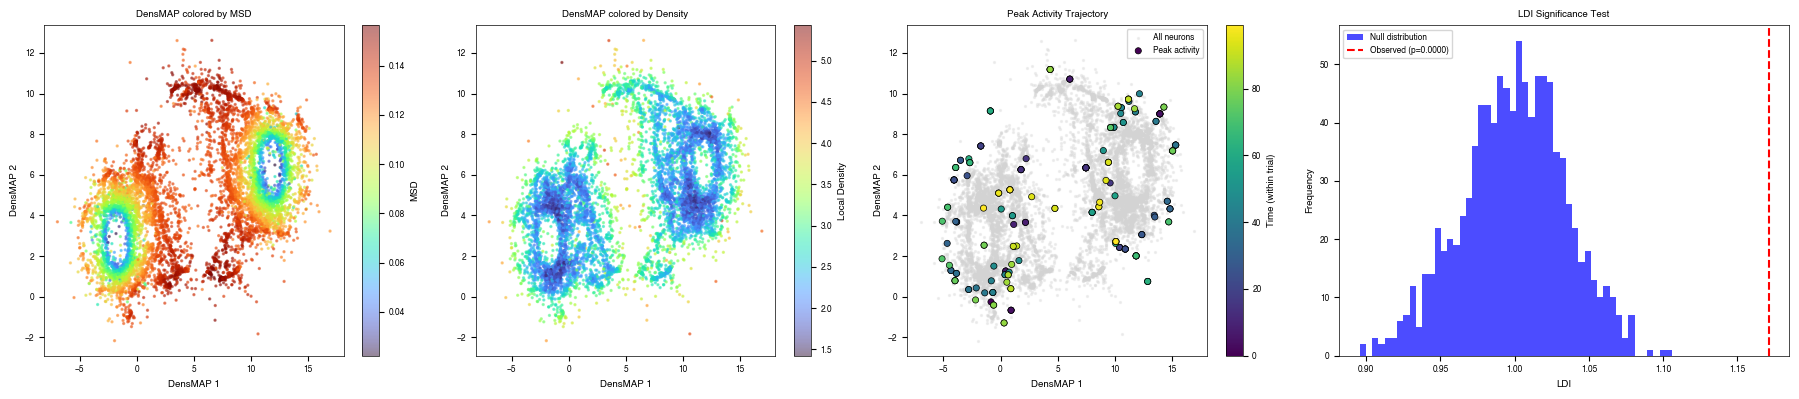

In [120]:
# Combined figure with 4 side by side subplots
print("Creating combined figure...")
fig = plt.figure(figsize=(18, 4))
gs = gridspec.GridSpec(1, 4, width_ratios=[1, 1, 1, 1.2])

# Subplot 1: DensMAP colored by MSD
ax1 = fig.add_subplot(gs[0])
scat1 = ax1.scatter(z_neurons_rnn[:, 0], z_neurons_rnn[:, 1], c=msd_rnn, cmap='turbo', s=2, alpha=.5)
plt.colorbar(scat1, ax=ax1, label='MSD')
ax1.set_title('DensMAP colored by MSD')
ax1.set_xlabel('DensMAP 1')
ax1.set_ylabel('DensMAP 2')

# Subplot 2: DensMAP colored by local density
ax2 = fig.add_subplot(gs[1])
scat2 = ax2.scatter(z_neurons_rnn[:, 0], z_neurons_rnn[:, 1], c=loc_density_rnn, cmap='turbo', s=2, alpha=.5)
plt.colorbar(scat2, ax=ax2, label='Local Density')
ax2.set_title('DensMAP colored by Density')
ax2.set_xlabel('DensMAP 1')
ax2.set_ylabel('DensMAP 2')

# Subplot 3: Peak Activity Locations
ax3 = fig.add_subplot(gs[2])
ax3.scatter(z_neurons_rnn[:, 0], z_neurons_rnn[:, 1], c='lightgray', s=2, alpha=0.3, label='All neurons')
colors = np.tile(np.arange(n_time_points), n_trials)
scat3 = ax3.scatter(peak_locations[:, 0], peak_locations[:, 1], c=colors, cmap='viridis', s=20, edgecolors='k', linewidths=0.5, label='Peak activity')
plt.colorbar(scat3, ax=ax3, label='Time (within trial)')
ax3.set_title('Peak Activity Trajectory')
ax3.set_xlabel('DensMAP 1')
ax3.set_ylabel('DensMAP 2')
ax3.legend(fontsize=6)

# Subplot 4: Null distribution of densities (LDI)
ax4 = fig.add_subplot(gs[3])
ax4.hist(null_ldis, bins=50, color='blue', alpha=0.7, label='Null distribution')
ax4.axvline(observed_ldi, color='red', linestyle='--', label=f'Observed (p={p_value_ldi:.4f})')
ax4.set_title('LDI Significance Test')
ax4.set_xlabel('LDI')
ax4.set_ylabel('Frequency')
ax4.legend(fontsize=6)

plt.tight_layout()
os.makedirs('../Figures', exist_ok=True)
plt.savefig('../Figures/linear_test_combined_plots.png', dpi=300)
plt.show()